# EN3160 Assignment 03

## Neural Network

---

**Name:** R.A.C.D. Ranawaka    
**Index Number:** 230526A  
**GitHub Link:** https://github.com/chaniruranawaka/Neural-Network

---

### Q1. Single Dense Layer Network - Modified

In [22]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [23]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

print("Training images:", len(trainset))
print("Testing images:", len(testset))

Training images: 50000
Testing images: 10000


In [24]:
# 2. Define Network Parameters
Din = 3 * 32 * 32   # Input size (flattened CIFAR-10 image size)
H = 100             # Middle layer with 100 nodes
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
epochs = 10
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []
epoch_losses = []

print("w1 shape:", w1.shape)
print("b1 shape:", b1.shape)
print("w2 shape:", w2.shape)
print("b2 shape:", b2.shape)

w1 shape: torch.Size([3072, 100])
b1 shape: torch.Size([100])
w2 shape: torch.Size([100, 10])
b2 shape: torch.Size([10])


In [25]:
# 3. Training Loop
for t in range(epochs):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_pred = h1.mm(w2) + b2

        # Cross-entropy loss
        loss = nn.functional.cross_entropy(y_pred, labels) + reg * (
            torch.sum(w1 * w1) + torch.sum(w2 * w2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        probs = torch.softmax(y_pred, dim=1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        dy_pred = (probs - y_train_onehot) / Ntr

        dw2 = h1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        dh1 = dy_pred.mm(w2.t())
        dz1 = dh1 * h1 * (1 - h1)

        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    epoch_loss = running_loss / len(trainloader)
    epoch_losses.append(epoch_loss)

    print(f"Epoch {t + 1}/{epochs}, Loss: {epoch_loss:.4f}")

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10, Loss: 2.3026
Epoch 2/10, Loss: 2.3026
Epoch 3/10, Loss: 2.3026
Epoch 4/10, Loss: 2.3026
Epoch 5/10, Loss: 2.3026
Epoch 6/10, Loss: 2.3026
Epoch 7/10, Loss: 2.3026
Epoch 8/10, Loss: 2.3026
Epoch 9/10, Loss: 2.3026
Epoch 10/10, Loss: 2.3026


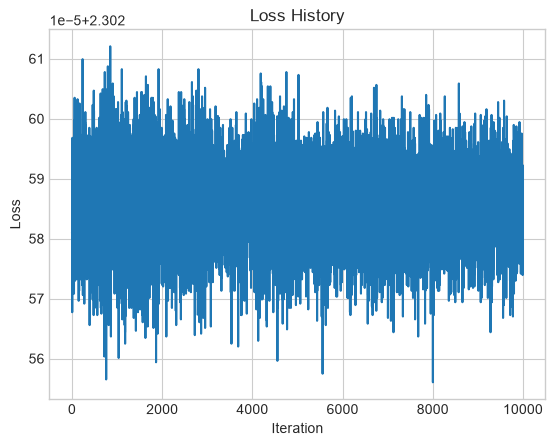

In [26]:
# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [27]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_train_pred = h1.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 10.00%


In [28]:
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        z1 = x_test.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_test_pred = h1.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 10.00%
